# Step 1: Missing Values and Missing Timestamps

## Setup & Load Data

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

energy = pd.read_csv("../data/raw/energy_dataset.csv")
weather = pd.read_csv("../data/raw/weather_features.csv")

# keep raw copies, we don't change the originals
energy_raw = energy.copy()
weather_raw = weather.copy()

# timestamps -> UTC
energy["time"] = pd.to_datetime(energy["time"], utc=True)
weather["dt_iso"] = pd.to_datetime(weather["dt_iso"], utc=True)

energy = energy.sort_values("time").set_index("time")
print("Energy:", energy.shape, "| Weather:", weather.shape)

Energy: (35064, 28) | Weather: (178396, 17)


## Missing Timestamps: Energy

In [2]:
full_range = pd.date_range(energy.index.min(), energy.index.max(), freq="h")
missing_ts = full_range.difference(energy.index)

print("Expected hours:", len(full_range))
print("Rows in energy:", len(energy))
print("Missing timestamps:", len(missing_ts))

Expected hours: 35064
Rows in energy: 35064
Missing timestamps: 0


## Missing Timestamps: Weather (per city)

In [3]:
for city, g in weather.groupby("city_name"):
    hours = pd.DatetimeIndex(g["dt_iso"].drop_duplicates())
    missing = full_range.difference(hours)
    print(f"{city:>10} | rows={len(g)} | unique hours={len(hours)} | missing hours={len(missing)}")

 Barcelona | rows=35476 | unique hours=35064 | missing hours=0
    Bilbao | rows=35951 | unique hours=35064 | missing hours=0
    Madrid | rows=36267 | unique hours=35064 | missing hours=0
   Seville | rows=35557 | unique hours=35064 | missing hours=0
  Valencia | rows=35145 | unique hours=35064 | missing hours=0


## Missing Values: Energy

In [4]:
na = energy.isna().sum()
na = na[na > 0].sort_values(ascending=False)

pd.DataFrame({"missing": na, "pct": (na / len(energy) * 100).round(3)})

,missing,pct
generation hydro pumped storage aggregated,35064,100.000
forecast wind offshore eday ahead,35064,100.000
total load actual,36,0.103
generation waste,19,0.054
generation marine,19,0.054
generation hydro pumped storage consumption,19,0.054
generation biomass,19,0.054
generation fossil oil,19,0.054
generation hydro run-of-river and poundage,19,0.054
generation fossil peat,18,0.051


## Missing Values: Weather

In [5]:
print("Total missing values in weather:", weather.isna().sum().sum())

Total missing values in weather: 0


<div dir="rtl">

### الاستنتاج: القيم الناقصة والـ timestamps الناقصة

- **الـ timestamps:** الطاقة كاملة (35,064 ساعة، 0 ناقص). الطقس كامل لكل مدينة (35,064 ساعة مختلفة لكل مدينة)، والصفوف الزايدة تكرار.
- **القيم الناقصة (الطاقة):** عمودين فاضيين تماماً (`generation hydro pumped storage aggregated` و`forecast wind offshore eday ahead`). الطلب ناقص 36 ساعة (0.103%)، و20 عمود توليد ناقص كل واحد 17 إلى 19 ساعة (حوالي 0.05%).
- **الطقس:** ما فيه قيم ناقصة.
- **الأثر على التنبؤ:** الطلب هدف، فالساعات الـ 36 ما لها قيمة نتدرب أو نقيّم عليها. وأي lag يعتمد عليها (24 أو 168 ساعة) يطلع فاضي بعدها بيوم أو أسبوع. التوليد يؤثر على هدفي المتجددة والأحفوري. العمودين الفاضيين ما يفيدون.
- **الخطوة الجاية:** نحدد وين الثغرات وكم طولها. ما نملا ولا نحذف شي قبل نقاش الفريق.

</div>

---

### Conclusion: Missing Values and Missing Timestamps

- **Timestamps:** Energy is complete (35,064 hours, 0 missing). Weather is complete for every city (35,064 unique hours each); the extra rows are duplicates.
- **Missing values (energy):** two columns are completely empty (`generation hydro pumped storage aggregated` and `forecast wind offshore eday ahead`). Demand is missing 36 hours (0.103%), and 20 generation columns are missing 17 to 19 hours each (about 0.05%).
- **Weather:** no missing values.
- **Impact on the forecast:** demand is a target, so those 36 hours have no value to train or evaluate on, and any lag that uses them (24h or 168h) becomes empty a day or a week later. Generation gaps affect the renewable and fossil targets. The two empty columns carry no information.
- **Next step:** locate the gaps and measure their length. We do not fill or remove anything before the team discusses it.

## Gap Locations and Lengths

In [6]:
def find_gaps(series):
    miss = series.isna()                         # True = this hour is missing
    block = (miss != miss.shift()).cumsum()      # number each consecutive block
    return (series.index.to_series()[miss]
            .groupby(block[miss])
            .agg(start="first", end="last", hours="count"))

In [7]:
demand_gaps = find_gaps(energy["total load actual"])
print("Number of gaps:", len(demand_gaps))
print(demand_gaps["hours"].value_counts().sort_index())
demand_gaps

Number of gaps: 22
hours
1    19
3     1
6     1
8     1
Name: count, dtype: int64


,start,end,hours
total load actual,,,
2,2015-01-05 11:00:00+00:00,2015-01-05 16:00:00+00:00,6
4,2015-01-28 12:00:00+00:00,2015-01-28 12:00:00+00:00,1
6,2015-02-01 06:00:00+00:00,2015-02-01 08:00:00+00:00,3
8,2015-02-01 11:00:00+00:00,2015-02-01 18:00:00+00:00,8
10,2015-04-05 01:00:00+00:00,2015-04-05 01:00:00+00:00,1
12,2015-04-16 07:00:00+00:00,2015-04-16 07:00:00+00:00,1
14,2015-04-20 06:00:00+00:00,2015-04-20 06:00:00+00:00,1
16,2015-04-23 19:00:00+00:00,2015-04-23 19:00:00+00:00,1
18,2015-05-02 08:00:00+00:00,2015-05-02 08:00:00+00:00,1


In [8]:
# generation columns that are not completely empty
gen_cols = [c for c in energy.columns
            if c.startswith("generation") and energy[c].notna().any()]

# NaN if ANY generation column is missing in that hour
gen_check = energy[gen_cols].sum(axis=1, min_count=len(gen_cols))

gen_gaps = find_gaps(gen_check)
print("Number of gaps:", len(gen_gaps))
print(gen_gaps["hours"].value_counts().sort_index())
gen_gaps

Number of gaps: 18
hours
1    16
2     1
6     1
Name: count, dtype: int64


,start,end,hours
2,2015-01-05 02:00:00+00:00,2015-01-05 02:00:00+00:00,1
4,2015-01-05 11:00:00+00:00,2015-01-05 16:00:00+00:00,6
6,2015-01-19 18:00:00+00:00,2015-01-19 19:00:00+00:00,2
8,2015-01-27 18:00:00+00:00,2015-01-27 18:00:00+00:00,1
10,2015-01-28 12:00:00+00:00,2015-01-28 12:00:00+00:00,1
12,2015-04-16 07:00:00+00:00,2015-04-16 07:00:00+00:00,1
14,2015-04-23 19:00:00+00:00,2015-04-23 19:00:00+00:00,1
16,2015-06-15 07:00:00+00:00,2015-06-15 07:00:00+00:00,1
18,2015-10-02 09:00:00+00:00,2015-10-02 09:00:00+00:00,1
20,2015-12-02 08:00:00+00:00,2015-12-02 08:00:00+00:00,1


<div dir="rtl">

### الاستنتاج: مواقع الثغرات وأطوالها

- **الطلب:** 36 ساعة ناقصة موزعة على 22 ثغرة. أغلبها (19) ساعة وحدة، والباقي 3 ثغرات أطول: 3 ساعات و6 ساعات و8 ساعات متتالية.
- **التوليد:** 24 ساعة ناقصة موزعة على 18 ثغرة (ساعة ناقص فيها أي عمود توليد). أغلبها (16) ساعة وحدة، وثغرة ساعتين، وأطولها 6 ساعات.
- **الأثر على التنبؤ:** كل ساعة ناقصة تخلي `lag_24h` و`lag_168h` فاضيين بعدها بيوم وبأسبوع، فتأثير الثغرة أكبر من طولها. الثغرات من ساعة وحدة أثرها صغير، والثغرات الطويلة (6 و8 ساعات) تسبب أكبر فقد في عينات التدريب.
- **القرار:** ما نملا ولا نحذف شي الحين. الطرق المقترحة للنقاش مع الفريق: ملء الثغرات القصيرة بالتوصيل بين القيمة قبلها وبعدها، واستبعاد أو معالجة الثغرات الطويلة بشكل منفصل.

</div>

---

### Conclusion: Gap Locations and Lengths

- **Demand:** 36 missing hours spread over 22 gaps. Most (19) are a single hour; the other 3 are longer: 3, 6 and 8 consecutive hours.
- **Generation:** 24 missing hours spread over 18 gaps (an hour where any generation column is missing). Most (16) are a single hour, one gap is 2 hours, and the longest is 6 hours.
- **Impact on the forecast:** each missing hour makes `lag_24h` and `lag_168h` empty one day and one week later, so a gap affects more rows than its length. Single-hour gaps have a small effect; the long gaps (6 and 8 hours) cause the largest loss of training samples.
- **Decision:**  Options to discuss with the team: fill short gaps by connecting the value before and after, and exclude or handle the long gaps separately.

# Step 2: Duplicate timestamps or more than one row for the same time.


## Duplicate Timestamps: Energy

In [9]:
print("Duplicate timestamps in energy:", energy.index.duplicated().sum())

Duplicate timestamps in energy: 0


## Duplicate Rows: Weather (same city + same hour)

In [10]:
key = ["city_name", "dt_iso"]
dup_mask = weather.duplicated(subset=key, keep=False)

print("Extra duplicate rows:", weather.duplicated(subset=key).sum())
print("Rows involved in duplicates:", dup_mask.sum())
print("Duplicate keys (city + hour):", weather[dup_mask].groupby(key).ngroups)
print()
print(weather[weather.duplicated(subset=key)]["city_name"].value_counts())

Extra duplicate rows: 3076
Rows involved in duplicates: 5874
Duplicate keys (city + hour): 2798

city_name
Madrid        1203
Bilbao         887
Seville        493
 Barcelona     412
Valencia        81
Name: count, dtype: int64


## Are the Duplicates Identical or Conflicting?

In [11]:
dups = weather[dup_mask]

num_cols = ["temp", "temp_min", "temp_max", "pressure", "humidity",
            "wind_speed", "wind_deg", "rain_1h", "rain_3h", "snow_3h", "clouds_all"]
text_cols = ["weather_id", "weather_main", "weather_description", "weather_icon"]

num_conflicts = (dups.groupby(key)[num_cols].nunique().max(axis=1) > 1).sum()
text_conflicts = (dups.groupby(key)[text_cols].nunique().max(axis=1) > 1).sum()

print("Keys with different numeric values:", num_conflicts)
print("Keys with different text values:", text_conflicts)
print("Exact full-row copies:", weather.duplicated().sum())

Keys with different numeric values: 0
Keys with different text values: 2777
Exact full-row copies: 21


## Example of One Duplicated Hour

In [12]:
dups.sort_values(key).head(6)

,dt_iso,city_name,temp,temp_min,temp_max,pressure,humidity,wind_speed,wind_deg,rain_1h,rain_3h,snow_3h,clouds_all,weather_id,weather_main,weather_description,weather_icon
109256,2015-03-20 20:00:00+00:00,Barcelona,286.81,282.59,291.48,1013,76,12,50,0.3,0.0,0.0,40,500,rain,light rain,10n
109257,2015-03-20 20:00:00+00:00,Barcelona,286.81,282.59,291.48,1013,76,12,50,0.3,0.0,0.0,40,301,drizzle,drizzle,09n
111170,2015-06-08 13:00:00+00:00,Barcelona,299.47,291.48,304.82,1017,57,3,180,12.0,0.0,0.0,20,503,rain,very heavy rain,10d
111171,2015-06-08 13:00:00+00:00,Barcelona,299.47,291.48,304.82,1017,57,3,180,12.0,0.0,0.0,20,211,thunderstorm,thunderstorm,11d
111172,2015-06-08 14:00:00+00:00,Barcelona,297.59,292.04,300.37,1017,54,2,170,3.0,0.0,0.0,20,502,rain,heavy intensity rain,10d
111173,2015-06-08 14:00:00+00:00,Barcelona,297.59,292.04,300.37,1017,54,2,170,3.0,0.0,0.0,20,211,thunderstorm,thunderstorm,11d


## City Names Check

In [13]:
print([repr(c) for c in weather["city_name"].unique()])

["'Valencia'", "'Madrid'", "'Bilbao'", "' Barcelona'", "'Seville'"]


<div dir="rtl">

### الاستنتاج: التكرار

- **الطاقة:** ما فيها timestamps مكررة (0).
- **الطقس:** 3,076 صف زايد في 2,798 ساعة-مدينة مكررة. أكثرها في Madrid (1,203) ثم Bilbao (887).
- **الأرقام:** نفس القيم في كل النسخ المكررة (0 تعارض في الأرقام)، فالحذف ما يضيع قياسات.
- **النصوص:** أعمدة `weather_main` و`weather_description` و`weather_icon` و`weather_id` تختلف في 2,777 ساعة-مدينة (مثلاً rain مع drizzle). يبدو إن المصدر يسجل أكثر من حالة جوية للساعة الواحدة، كل حالة في صف.
- **الأسماء:** اسم المدينة `' Barcelona'` فيه مسافة في أوله.
- **الأثر على التنبؤ:** لو دمجنا الطقس مع الطاقة بدون معالجة التكرار، الساعات المكررة تضاعف صفوف الطاقة، فيتشوه عدد العينات وتتكرر بعض الساعات في التدريب. ولو تركنا مسافة برشلونة، المقارنة بالاسم تفشل بدون ما ننتبه.
- **القرار:** ما نحذف شي الحين. المقترح للنقاش: نشيل المسافة، ونحذف التكرار حسب (المدينة + الساعة)، ونقرر كيف نتعامل مع أعمدة النص (نتجنبها، أو نختار حالة وحدة بقاعدة واضحة).

</div>

---

### Conclusion: Duplicates

- **Energy:** no duplicate timestamps (0).
- **Weather:** 3,076 extra rows across 2,798 duplicated city-hour keys, mostly in Madrid (1,203) and Bilbao (887).
- **Numbers:** all numeric values are identical across duplicates (0 conflicts), so removing them loses no measurements.
- **Text:** `weather_main`, `weather_description`, `weather_icon` and `weather_id` differ in 2,777 city-hour keys (e.g. rain vs drizzle). The source seems to record more than one weather condition per hour, one per row.
- **City names:** the name `' Barcelona'` has a leading space.
- **Impact on the forecast:** merging weather into energy without handling duplicates would multiply energy rows for the duplicated hours, distorting the sample count and repeating some hours in training. Leaving the Barcelona space would make name-based matching fail silently.
- **Decision:** Proposal for discussion: strip the space, drop duplicates by (city + hour), and decide how to treat the text columns (avoid them, or pick one condition with a clear rule).

# Step 3: Values that are impossible or outside expected ranges.

## Temporary Copy of Weather (no duplicates)

In [14]:
# temporary copy for plotting only, the original weather table is not changed
wd = weather.drop_duplicates(["city_name", "dt_iso"])

## Boxplots: Energy

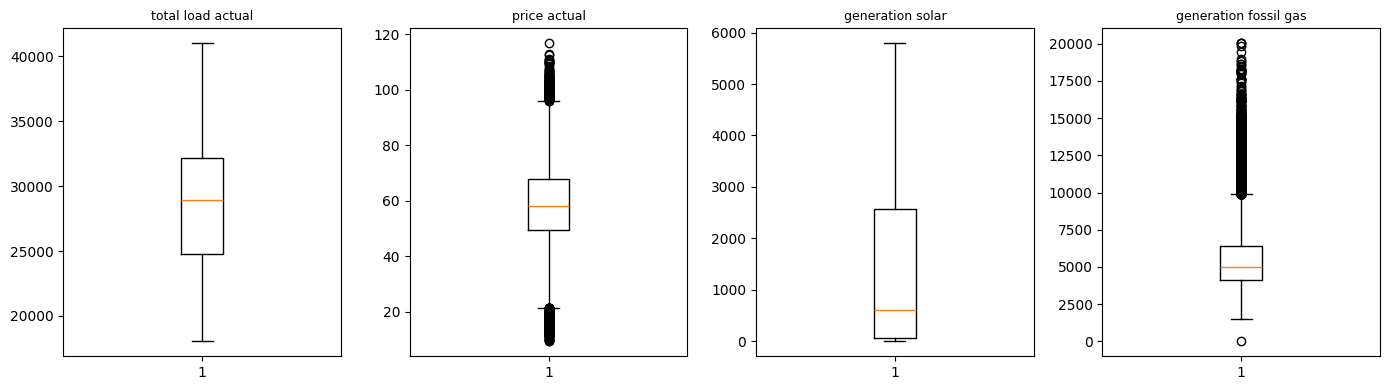

In [15]:
cols = ["total load actual", "price actual", "generation solar", "generation fossil gas"]

fig, axes = plt.subplots(1, len(cols), figsize=(14, 4))
for ax, c in zip(axes, cols):
    ax.boxplot(energy[c].dropna())
    ax.set_title(c, fontsize=9)
plt.tight_layout()
plt.show()

## Boxplots: Weather

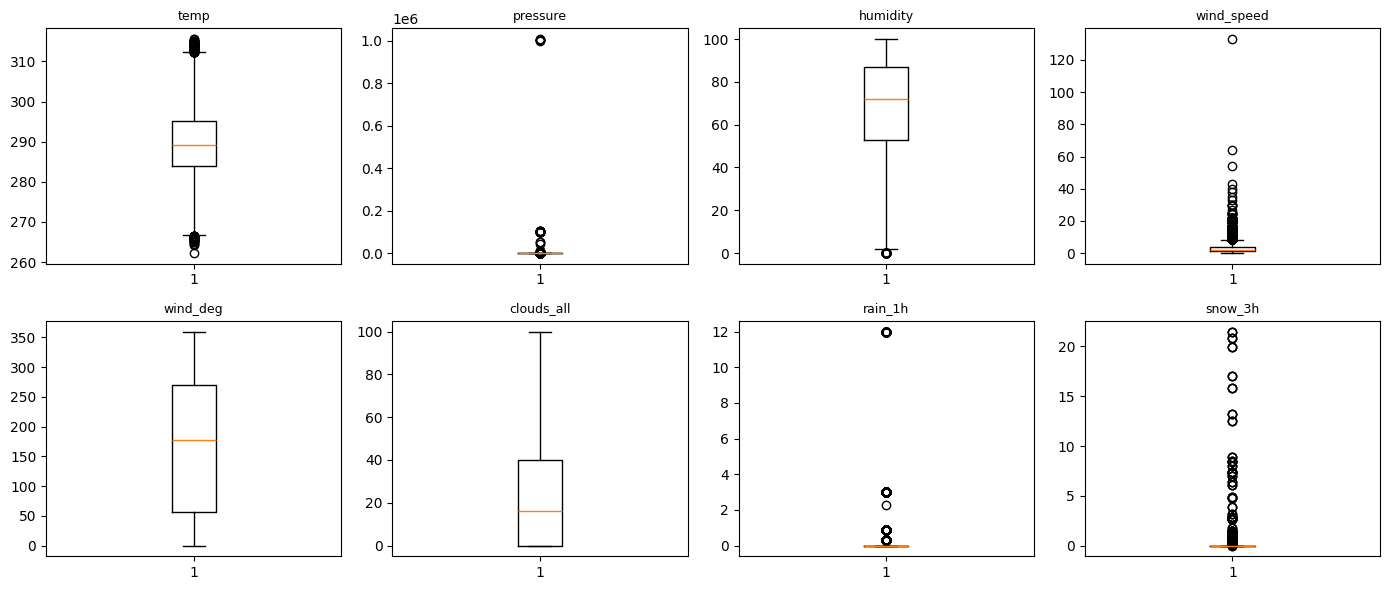

In [16]:
wcols = ["temp", "pressure", "humidity", "wind_speed",
         "wind_deg", "clouds_all", "rain_1h", "snow_3h"]

fig, axes = plt.subplots(2, 4, figsize=(14, 6))
for ax, c in zip(axes.flat, wcols):
    ax.boxplot(wd[c])
    ax.set_title(c, fontsize=9)
plt.tight_layout()
plt.show()

## Min and Max: Energy

In [17]:
energy_num = energy.select_dtypes("number").dropna(axis=1, how="all")
energy_num.agg(["min", "max"]).T

,min,max
generation biomass,0.00,592.00
generation fossil brown coal/lignite,0.00,999.00
generation fossil coal-derived gas,0.00,0.00
generation fossil gas,0.00,20034.00
generation fossil hard coal,0.00,8359.00
generation fossil oil,0.00,449.00
generation fossil oil shale,0.00,0.00
generation fossil peat,0.00,0.00
generation geothermal,0.00,0.00
generation hydro pumped storage consumption,0.00,4523.00


## Min and Max: Weather

In [18]:
num_cols = ["temp", "temp_min", "temp_max", "pressure", "humidity", "wind_speed",
            "wind_deg", "rain_1h", "rain_3h", "snow_3h", "clouds_all"]
wd[num_cols].agg(["min", "max"]).T

,min,max
temp,262.24,315.600
temp_min,262.24,315.150
temp_max,262.24,321.150
pressure,0.00,1008371.000
humidity,0.00,100.000
wind_speed,0.00,133.000
wind_deg,0.00,360.000
rain_1h,0.00,12.000
rain_3h,0.00,2.315
snow_3h,0.00,21.500


## How Many Impossible Readings?

In [19]:
# Limits based on known ranges:
# pressure: normal sea-level pressure is roughly 900-1100 hPa
# wind: Beaufort scale, force 11 (violent storm) starts at 28.5 m/s
PRESSURE_MIN, PRESSURE_MAX = 900, 1100
WIND_LIMIT = 28.5

checks = {
    f"pressure outside {PRESSURE_MIN}-{PRESSURE_MAX}": (wd["pressure"] < PRESSURE_MIN) | (wd["pressure"] > PRESSURE_MAX),
    f"wind_speed >= {WIND_LIMIT} (Beaufort 11+)": wd["wind_speed"] >= WIND_LIMIT,
    "humidity = 0": wd["humidity"] == 0,
}
for name, mask in checks.items():
    print(name, "| rows:", mask.sum(), "|", wd[mask]["city_name"].value_counts().to_dict())

pressure outside 900-1100 | rows: 48 | {' Barcelona': 48}
wind_speed >= 28.5 (Beaufort 11+) | rows: 12 | {'Valencia': 12}
humidity = 0 | rows: 63 | {' Barcelona': 61, 'Madrid': 2}


## Wind Speed by Beaufort Class

In [20]:
bins = [0, 24.5, 28.5, 32.7, float("inf")]
labels = ["below storm", "storm (force 10)", "violent storm (force 11)", "hurricane force (force 12)"]

pd.cut(wd["wind_speed"], bins=bins, labels=labels, right=False).value_counts().sort_index()

wind_speed
below storm                   175304
storm (force 10)                   4
violent storm (force 11)           4
hurricane force (force 12)         8
Name: count, dtype: int64

## Zeros in Gas and Nuclear

In [23]:
# Check zeros in generation columns where zero is unexpected:
# - fossil gas and nuclear usually run continuously, so a value of 0 is suspicious
# - (solar at night or low wind can be 0 normally, so we do not check them here)

for c in ["generation fossil gas", "generation nuclear"]:
    z = energy[c] == 0                          # True for hours where the value is exactly 0
    print(c, "| zero hours:", z.sum())          # how many hours have zero
    print(energy.index[z][:10])                 # dates of the first 10 zero hours

generation fossil gas | zero hours: 1
DatetimeIndex(['2018-06-02 09:00:00+00:00'], dtype='datetime64[ns, UTC]', name='time', freq=None)
generation nuclear | zero hours: 3
DatetimeIndex(['2017-11-12 20:00:00+00:00', '2017-11-14 11:00:00+00:00',
               '2017-11-14 18:00:00+00:00'],
              dtype='datetime64[ns, UTC]', name='time', freq=None)


<div dir="rtl">

### الاستنتاج: القيم المستحيلة أو خارج المدى

الـ boxplot يطلع القيم الشاذة إحصائياً، والـ min/max نقارنه بالحدود الواقعية. الشاذ مو بالضرورة خطأ.

- **الطلب والسعر:** ضمن المدى المنطقي (الطلب 18,041–41,015، السعر 9.33–116.80). السعر فيه شاذة عالية وواطية لكنها أسعار حقيقية، فنبقيها.
- **التوليد:** ما فيه قيم سالبة. 6 أعمدة كلها صفر (`coal-derived gas` و`oil shale` و`peat` و`geothermal` و`marine` و`wind offshore`) فما تحمل معلومة.
- **أصفار مشبوهة:** الغاز صفر في ساعة وحدة (2018-06-02 09:00 UTC)، والنووي صفر في 3 ساعات (2017-11-12 و2017-11-14). قليلة ومعزولة، وتحتاج فحص.
- **الطقس (الحدود المستخدمة):** الضغط 900–1100 هكتوباسكال، والرياح 28.5 م/ث (بداية العاصفة العنيفة حسب بوفورت)، والرطوبة 0.
- **الضغط:** 48 قراءة خارج المدى (من 0 إلى 1,008,371)، كلها في برشلونة.
- **الرياح:** 12 قراءة ≥ 28.5 م/ث (وصلت 133 م/ث)، كلها في فالنسيا.
- **الرطوبة:** 63 قراءة بقيمة 0 (برشلونة 61، مدريد 2).
- **تركز الأخطاء:** كل مشكلة تتركز في مدينة معينة، وهذا يلمح إلى عطل في الحساس مو طقس حقيقي.
- **سليم:** `temp` (262.24–315.60 كلفن)، و`wind_deg`، و`clouds_all`، والمطر والثلج.
- **الأثر على التنبؤ:** القيم المستحيلة لو دخلت كفيتشرز تشوه الموديل (الضغط بالملايين يخرب أي مقياس)، والأعمدة الصفرية بدون فايدة. القيم الحقيقية الشاذة (السعر) لازم تبقى، لأن الموديل لازم يتعلم الارتفاعات.
- **القرار:** ما نعدل ولا نحذف شي الحين. المقترح للنقاش: نعتبر القيم المستحيلة مفقودة (NaN) ونتعامل معها مثل الثغرات، ونبقي الشاذ الحقيقي، ونفحص أصفار الغاز والنووي.

</div>

---

### Conclusion: Impossible or Out-of-Range Values

The boxplot shows statistical outliers; min/max is compared against real-world limits. An outlier is not necessarily an error.

- **Demand and price:** within realistic ranges (demand 18,041–41,015, price 9.33–116.80). Price has high and low outliers, but they are real prices, so we keep them.
- **Generation:** no negative values. Six columns are all zeros (`coal-derived gas`, `oil shale`, `peat`, `geothermal`, `marine`, `wind offshore`), so they carry no information.
- **Suspicious zeros:** fossil gas is 0 in one hour (2018-06-02 09:00 UTC), and nuclear is 0 in three hours (2017-11-12 and 2017-11-14). They are few and isolated, and need checking.
- **Weather (limits used):** pressure 900–1100 hPa, wind speed 28.5 m/s (start of a violent storm on the Beaufort scale), humidity 0.
- **Pressure:** 48 readings outside the range (from 0 up to 1,008,371), all in Barcelona.
- **Wind:** 12 readings ≥ 28.5 m/s (up to 133 m/s), all in Valencia.
- **Humidity:** 63 readings equal to 0 (Barcelona 61, Madrid 2).
- **Concentration:** each problem is concentrated in a specific city, which points to a sensor fault rather than real weather.
- **Valid:** `temp` (262.24–315.60 K), `wind_deg`, `clouds_all`, rain and snow.
- **Impact on the forecast:** impossible values used as features would distort the model (pressure in the millions breaks any scaling), and all-zero columns add nothing. Real extremes (price) must stay, because the model has to learn the spikes.
- **Decision:** Proposal for discussion: treat impossible values as missing (NaN) and handle them like gaps, keep real extremes, and check the gas and nuclear zeros.

# Step 4: Sudden changes in units, sensors, or data collection.


## When Do the Suspicious Weather Values Happen?

In [26]:
issues = {
    "pressure": (wd["pressure"] < 900) | (wd["pressure"] > 1100),
    "wind_speed >= 28.5": wd["wind_speed"] >= 28.5,
    "humidity = 0": wd["humidity"] == 0,
}
for name, mask in issues.items():
    bad = wd[mask]
    print(name, "| first:", bad["dt_iso"].min(), "| last:", bad["dt_iso"].max())
    print(bad["dt_iso"].dt.strftime("%Y-%m").value_counts().sort_index().to_dict())
    print()

pressure | first: 2015-02-20 08:00:00+00:00 | last: 2015-07-18 02:00:00+00:00
{'2015-02': 47, '2015-07': 1}

wind_speed >= 28.5 | first: 2015-01-16 12:00:00+00:00 | last: 2017-05-11 10:00:00+00:00
{'2015-01': 9, '2015-02': 2, '2017-05': 1}

humidity = 0 | first: 2015-02-09 13:00:00+00:00 | last: 2015-03-30 11:00:00+00:00
{'2015-02': 61, '2015-03': 2}



## Isolated Hours or Lasting?

In [27]:
def runs_for(city, col, is_bad):
    s = wd[wd["city_name"] == city].set_index("dt_iso").sort_index()[col]
    return find_gaps(s.where(~is_bad(s)))     # bad hours become NaN, then same gap function

p_runs = runs_for(" Barcelona", "pressure", lambda s: (s < 900) | (s > 1100))
w_runs = runs_for("Valencia", "wind_speed", lambda s: s >= 28.5)
h_runs = runs_for(" Barcelona", "humidity", lambda s: s == 0)

for name, r in [("pressure", p_runs), ("wind_speed", w_runs), ("humidity", h_runs)]:
    print(name, "| groups:", len(r))
    print(r["hours"].value_counts().sort_index().to_dict())
    print()
p_runs

pressure | groups: 9
{1: 2, 2: 1, 3: 1, 4: 1, 8: 1, 9: 2, 11: 1}

wind_speed | groups: 8
{1: 4, 2: 4}

humidity | groups: 13
{1: 6, 2: 1, 4: 1, 5: 1, 6: 1, 8: 1, 14: 1, 16: 1}



,start,end,hours
pressure,,,
2,2015-02-20 08:00:00+00:00,2015-02-20 15:00:00+00:00,8
4,2015-02-20 17:00:00+00:00,2015-02-21 01:00:00+00:00,9
6,2015-02-21 04:00:00+00:00,2015-02-21 14:00:00+00:00,11
8,2015-02-21 16:00:00+00:00,2015-02-21 18:00:00+00:00,3
10,2015-02-21 21:00:00+00:00,2015-02-22 00:00:00+00:00,4
12,2015-02-22 03:00:00+00:00,2015-02-22 11:00:00+00:00,9
14,2015-02-22 13:00:00+00:00,2015-02-22 13:00:00+00:00,1
16,2015-02-22 19:00:00+00:00,2015-02-22 20:00:00+00:00,2
18,2015-07-18 02:00:00+00:00,2015-07-18 02:00:00+00:00,1


## Plot Around the First Wind Outlier

<Axes: title={'center': 'Valencia wind_speed around first outlier'}, xlabel='dt_iso'>

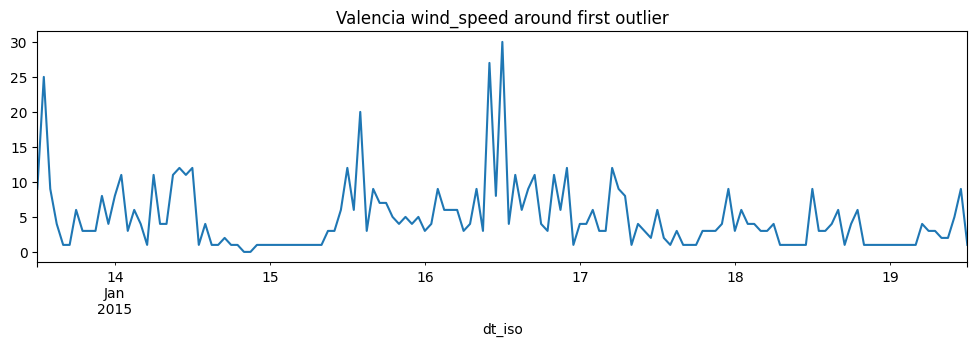

In [28]:
v = wd[wd["city_name"] == "Valencia"].set_index("dt_iso").sort_index()["wind_speed"]
first = v[v >= 28.5].index.min()
v[first - pd.Timedelta(days=3): first + pd.Timedelta(days=3)].plot(figsize=(12, 3), title="Valencia wind_speed around first outlier")

## Yearly Level Check

In [30]:
cols = ["total load actual", "price actual", "generation solar",
        "generation wind onshore", "generation fossil gas", "generation nuclear"]
energy[cols].groupby(energy.index.year).mean().round(0)

,total load actual,price actual,generation solar,generation wind onshore,generation fossil gas,generation nuclear
time,,,,,,
2014,25385.0,65.0,49.0,6378.0,4844.0,7096.0
2015,28359.0,61.0,1457.0,5477.0,5057.0,6249.0
2016,28508.0,47.0,1406.0,5416.0,5142.0,6378.0
2017,28857.0,59.0,1495.0,5381.0,6473.0,6346.0
2018,29064.0,63.0,1373.0,5584.0,5819.0,6082.0


In [31]:
# median is used so the bad readings do not distort the result
wd.groupby([wd["dt_iso"].dt.year, "city_name"])[["temp", "pressure", "humidity", "wind_speed"]].median().round(1)

temp  pressure  humidity  wind_speed
dt_iso city_name                                        
2014    Barcelona  281.6    1035.0     100.0         7.0
       Bilbao      269.7    1036.0      97.0         0.0
       Madrid      267.3     971.0      63.0         1.0
       Seville     273.4    1039.0      75.0         1.0
       Valencia    270.5    1001.0      77.0         1.0
2015    Barcelona  289.2    1018.0      76.0         3.0
       Bilbao      286.1    1020.0      83.0         1.0
       Madrid      287.2    1016.0      60.0         2.0
       Seville     294.0    1020.0      65.0         2.0
       Valencia    289.8    1016.0      68.0         2.0
2016    Barcelona  289.3    1017.0      78.0         3.0
       Bilbao      286.2    1016.0      82.0         1.0
       Madrid      286.1    1017.0      61.5         2.0
       Seville     293.3    1019.0      71.0         2.0
       Valencia    289.8    1017.0      67.0         2.0
2017    Barcelona  289.6    1018.0      73.0         2.0
       Bilbao      286.3    1020.0      82.0         1.0
       Madrid      288.2    1019.0      52.0         2.0
       Seville     292.9    1017.0      62.0         2.0
       Valencia    291.2    1018.0      66.0         2.0
2018    Barcelona  289.6    1016.0      76.0         2.0
       Bilbao      286.3    1018.0      82.0         2.0
       Madrid      286.4    1017.0      62.0         2.0
       Seville     289.5    1016.0      71.0         2.0
       Valencia    291.2    1016.0      65.0         2.0

## 30-Day Rolling Average

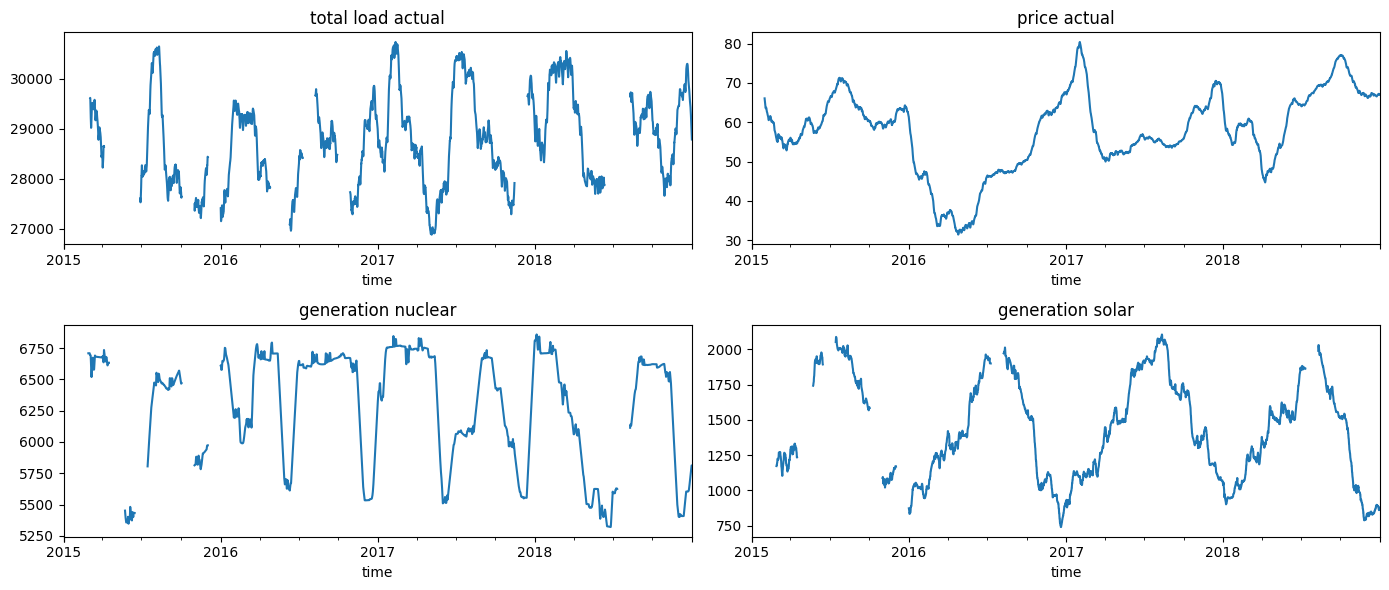

In [32]:
cols = ["total load actual", "price actual", "generation nuclear", "generation solar"]
fig, axes = plt.subplots(2, 2, figsize=(14, 6))
for ax, c in zip(axes.flat, cols):
    energy[c].rolling(24 * 30).mean().plot(ax=ax, title=c)
plt.tight_layout()
plt.show()

## Price Spikes: Isolated or Lasting?

In [33]:
p = energy["price actual"]
spike_runs = find_gaps(p.where(p <= p.quantile(0.99)))
print(spike_runs["hours"].value_counts().sort_index())
spike_runs.sort_values("hours", ascending=False).head(10)

hours
1     22
2     17
3     20
4     12
5      7
6      2
7      2
16     1
17     1
18     3
19     1
20     1
Name: count, dtype: int64


,start,end,hours
price actual,,,
130,2017-01-25 06:00:00+00:00,2017-01-26 01:00:00+00:00,20
128,2017-01-24 06:00:00+00:00,2017-01-25 00:00:00+00:00,19
116,2017-01-19 06:00:00+00:00,2017-01-19 23:00:00+00:00,18
118,2017-01-20 06:00:00+00:00,2017-01-20 23:00:00+00:00,18
126,2017-01-23 06:00:00+00:00,2017-01-23 23:00:00+00:00,18
132,2017-01-26 06:00:00+00:00,2017-01-26 22:00:00+00:00,17
114,2017-01-18 07:00:00+00:00,2017-01-18 22:00:00+00:00,16
122,2017-01-21 17:00:00+00:00,2017-01-21 23:00:00+00:00,7
96,2017-01-12 07:00:00+00:00,2017-01-12 13:00:00+00:00,7


<div dir="rtl">

**Sudden changes: الاستنتاج**

- لقينا قراءات غلط في 3 أعمدة من الطقس: الضغط (48 قراءة)، والرطوبة = 0 (63 قراءة)، والرياح ≥ 28.5 (12 قراءة). المجموع حوالي 123 قراءة من 175,320.
- هذي القراءات متجمعة في بداية 2015 (يناير–مارس تقريباً)، ومن مدن محددة: الضغط والرطوبة من Barcelona، والرياح من Valencia. يعني المشكلة في حساسات معينة وفي فترة قصيرة، وما هي موزعة على السنين.
- فحصنا المتوسط السنوي والرسم المتحرك (30 يوم) لأعمدة الطاقة (الطلب والسعر والنووي والشمس)، وما لقينا قفزة دائمة. الانقطاعات اللي في الرسم سببها الـ gaps. يعني الوحدات والحساسات ما تغيرت على مدى السنين.
- القرار المقترح: نحول القيم الغلط إلى NaN ونعاملها مثل الـ gaps، وما نحذف الصفوف. تأثيرها على الموديل صغير لأنها قليلة ومن فترة قديمة.

</div>

---

**Sudden changes: Conclusion**

- We found bad readings in 3 weather columns: pressure (48 readings), humidity = 0 (63), and wind speed ≥ 28.5 (12). In total about 123 out of 175,320 readings.
- They are clustered in early 2015 (roughly Jan–Mar) and in specific cities: pressure and humidity from Barcelona, wind from Valencia. So the problem is specific sensors in a short period, not spread across the years.
- We checked yearly averages and 30-day rolling plots for the energy columns (demand, price, nuclear, solar) and found no permanent jumps. The breaks in the plots come from gaps. So units and sensors did not change over the years.
- Proposed decision: set the bad values to NaN and treat them like the gaps, without deleting rows. The impact on the model is small because they are few and from an early period.

# Step 5 : Whether the time interval stays regular across the full dataset.


## 7. Time Interval Regularity

In [ ]:
# Time interval between consecutive rows (should be exactly 1 hour everywhere)
print("Energy:")
print(energy.index.to_series().diff().value_counts())

print("\nWeather (per city, after temporary de-duplication):")
for city, g in wd.groupby("city_name"):
    diffs = g.sort_values("dt_iso")["dt_iso"].diff().value_counts().to_dict()
    print(city, diffs)

Energy:
time
0 days 01:00:00    35063
Name: count, dtype: int64

Weather (per city, after temporary de-duplication):
 Barcelona {Timedelta('0 days 01:00:00'): 35063}
Bilbao {Timedelta('0 days 01:00:00'): 35063}
Madrid {Timedelta('0 days 01:00:00'): 35063}
Seville {Timedelta('0 days 01:00:00'): 35063}
Valencia {Timedelta('0 days 01:00:00'): 35063}


Time Interval Regularity: Conclusion

The time interval is regular: exactly one hour between every pair of consecutive rows across the full dataset.
Energy has 35,064 hours with no missing or duplicate timestamps, and each weather city has the same count after removing duplicates.
So the only holes in the data are the missing values (NaN) we found earlier, not missing timestamps.
Result: we can build the 24h and 168h lags directly with row shifts (shift(24)), as long as we keep the full hourly index.